# Step 3 · Present score of the firms · Underwater drones

**PW Innovation Management · Team 10 · client: Fincantieri** · notebook `04_present_score`

The bank asks: **which firms of the sector hold the most valuable patent portfolios today?** The present score
answers with one number per firm, built on what has *already happened* to its patents: citations received,
decisions of the examiners, countries where they are protected. It follows Tutorial 4 (notebook 40), which takes
the four criteria of the Clarivate *Top 100 Global Innovators* and measures them inside one sector.

| Dimension | Question | Our indicator (basics) | Lecture |
|---|---|---|---|
| **Volume** | how much does the firm invent? | share of the sector's families in the scoring window | size |
| **Influence** | do others build on its inventions? | forward citations within 5 years ÷ mean of the sector's families of the same priority year (1 = average) | technological |
| **Success** | do the examiners accept them? | share of the national applications of each family that are granted, averaged over the firm's families (Tutorial 4, 6.2) | legal |
| **Globalization** | are they protected in the main markets? | distinct offices per family, without PCT requests (`WO`) and EP translations (kind `T`) | economic |

It reads the clean tables of `02_clean` (`outputs/<env>/step1/`, PROD run of 23 November 2026) and needs no
PATSTAT query.

**Design decisions** (settings in `config/sector.yaml`, section `present_score`; to justify in the technical
appendix):

| Decision | Choice | Why |
|---|---|---|
| Scoring window | priority years **2010-2019** | grants: applications filed by 2019 have mostly been decided (`GRANT_MAX_YEAR`, Step 2); citations: families up to 2017 have a complete 5-year window, later ones count as missing, not as zero (Tutorial 4, 5.1). Before 2010 the sector has fewer than 140 families a year |
| Firms scored | firms (and unclassified companies) with at least **10 families in the window** | the Clarivate volume gate, scaled to one sector: with fewer families one citation or one refusal changes a rate completely |
| Success | family level, across offices (Tutorial 4, 6.2), not the EP grant rate (6.1) | 73% of the families are first filed in China and few have an EP member: an EP-only measure would score a handful of firms. The EP rate is kept as a refinement |
| Combination | Reciprocal Rank Fusion (RRF), c = number of firms | volume is very skewed (one state group has many times the median portfolio): with the ratio to the mean it would decide alone (Tutorial 4, 8.3) |
| Weights | influence 35%, globalization 30%, success 20%, volume 15% | Section 3 |
| Client and market leaders | references, not ranked | the client is the buyer; most leaders are below the gate (1.5.1) |
| Young firms | firms of the Step 2 shortlist below the gate in the window | their value is in recent filings: Step 4 (future score) |

## 0 · Setup

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=FutureWarning)

# ---------------------------------------------------------------- the repository's src/ folder (config.py, pw_utils.py)
_here = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd().resolve()   # script or notebook
SRC_DIR = next((d / "src" for d in (_here, *_here.parents) if (d / "src" / "config.py").exists()), None)
if SRC_DIR is None:
    raise FileNotFoundError("src/config.py not found: run this notebook from inside the repository (notebooks/ or src/)")
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))
import config as C                         # config/sector.yaml: env, client, present_score settings
from pw_utils import combine_scores, final_rank, to_group   # tested in tests/

IN = C.OUT_STEP1                           # outputs/<env>/step1: the clean tables of 02_clean
IN2 = C.OUT_STEP2                          # outputs/<env>/step2: the Step 2 shortlist (for the young firms)
OUT = C.OUT_STEP3                          # outputs/<env>/step3: this notebook
FIG, TAB = OUT / "figures", OUT / "tables"
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)

P = C.PRESENT
METHOD = P.get("method", "rrf")
WEIGHTS = dict(P.get("weights") or {"influence": 0.35, "globalization": 0.30, "success": 0.20, "volume": 0.15})
WINDOW = tuple(P.get("window", [2010, 2019]))
MIN_FAMILIES = int(P.get("min_families", 10))
MID_YEAR = (WINDOW[0] + WINDOW[1]) // 2    # first half / second half of the window (volume change)
TOP_SHARE = 0.10                           # blocking patents: top 10% of each priority year (Tutorial 4, 5.4)
QUAD = {"CN", "EP", "JP", "US"}            # quadrilateral family (Clarivate; Tutorial 4, 7.3)
REFERENCE_FIRMS = list(P.get("reference_firms") or [])
CLIENT = C.CLIENT
INDICATORS = ["volume", "influence", "success", "globalization"]

NAVY, ORANGE, BLUE, GREY, MID, LIGHT, GREEN, RED = ("#002B49", "#EF7B00", "#4F7CA3", "#4A5A6A", "#8A9AAB",
                                                    "#D9E1E8", "#7A9A3A", "#A23B72")
COLOURS = {"influence": NAVY, "globalization": MID, "success": BLUE, "volume": ORANGE}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
                     "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left"})
pd.set_option("display.max_colwidth", 40)
print(f"env {C.ENV} · window {WINDOW} · gate {MIN_FAMILIES} families · method {METHOD} · weights {WEIGHTS}")

env PROD · window (2010, 2019) · gate 10 families · method rrf · weights {'influence': 0.35, 'globalization': 0.3, 'success': 0.2, 'volume': 0.15}


## 1 · Data: families, applications, owners

The same preparation as `03_landscape` §0.1: applicants carry the harmonised group name of `02_clean`, the corporate
groups of `config.GROUP_ALIASES` are re-applied, one type per group (from the applicant profile). A family filed by
two firms counts for **both** (full counting, as in Tutorial 4).

**Applications.** Two kinds of family members are not national applications and are left out of success and
globalization (Tutorial 4, 6.2): PCT requests (`WO`) and translations of granted EP patents (kind `T`, recorded as
national applications by some offices).

In [2]:
fam = pd.read_csv(IN / "families.csv", low_memory=False,
                  usecols=["docdb_family_id", "family_year", "first_publn_year", "fwd_cits_5y", "fwd_window_complete",
                           "fwd_X_cits", "is_international"])
apps = pd.read_csv(IN / "applications.csv", low_memory=False,
                   usecols=["appln_id", "docdb_family_id", "appln_auth", "appln_kind", "is_granted"])
appl = pd.read_csv(IN / "applicants.csv", low_memory=False)
prof = pd.read_csv(IN / "applicants_profile.csv", low_memory=False)
legal = pd.read_csv(IN / "legal_events.csv.gz", low_memory=False,
                    usecols=["appln_id", "event_auth", "event_code", "fee_country", "docdb_family_id"])

# corporate groups and one type per group (as 03_landscape §0.1)
appl["applicant"] = appl["applicant"].map(lambda a: to_group(a) if isinstance(a, str) else a)
prof["applicant"] = prof["applicant"].map(lambda a: to_group(a) if isinstance(a, str) else a)
group_type = prof.sort_values("families", ascending=False).drop_duplicates("applicant").set_index("applicant")["type"]
appl["type"] = appl["applicant"].map(group_type).fillna(appl["applicant_type"])
appl.loc[appl["applicant"].eq(CLIENT), "type"] = "firm"
country = (appl.dropna(subset=["country"]).groupby("applicant")["country"].agg(lambda s: s.mode().iat[0]))
links = appl[["docdb_family_id", "applicant", "type", "family_year"]].drop_duplicates(["docdb_family_id", "applicant"])

# national applications: no PCT requests, no EP translations
apps["appln_auth"] = apps["appln_auth"].astype(str).str.strip()
apps["appln_kind"] = apps["appln_kind"].astype(str).str.strip()
national = apps[(apps.appln_auth != "WO") & (apps.appln_kind != "T")].drop_duplicates("appln_id")
print(f"{len(fam):,} families · {len(apps):,} applications, of which {len(national):,} national "
      f"({(apps.appln_auth == 'WO').sum():,} PCT requests and {(apps.appln_kind == 'T').sum():,} EP translations left out)")

# the scoring window
in_win = fam["family_year"].between(*WINDOW)
win = fam[in_win].copy()
print(f"Window {WINDOW[0]}-{WINDOW[1]}: {len(win):,} families "
      f"({win.fwd_window_complete.mean():.0%} with a complete 5-year citation window)")

15,694 families · 20,005 applications, of which 18,619 national (1,158 PCT requests and 228 EP translations left out)
Window 2010-2019: 5,176 families (59% with a complete 5-year citation window)


## 2 · Indicators of each family

Four basic measures and three refinements, family by family, before aggregating them to the firms.

- **Influence**: `fwd_cits_5y` (distinct citing families within 5 years of the priority year, `02_clean` §6) ÷ the
  mean of the sector's families of the same priority year; missing when the window is not complete.
- **Success**: share of the family's national applications that are granted.
- **Globalization**: distinct offices of the national applications (EP counts as one office).
- **Quadrilateral** (refinement 7.3): the family is filed at CN, EP, JP and US.
- **Blocking** (refinement 5.4): the family is in the top 10% of its priority year by citing families that cite it
  as **X** (blocking prior art), with at least one. `02_clean` records X; I categories are not separated.
- **EP states** (refinement 7.2): for the granted EP applications, the states where a renewal fee was paid
  (`PGFP` events). The PG25 lapses in our extract carry no reason, so states never validated cannot be told apart
  from states that lapsed for non-payment: the count is a **lower bound** on the validated states.

In [3]:
def cohort_ratio(values, years):
    """Each family's value ÷ the mean of the families of the same priority year (missing stays missing)."""
    mean_year = values.groupby(years).transform("mean")
    return (values / mean_year).where(mean_year > 0, 0.0).where(values.notna())


win["fwd5"] = win["fwd_cits_5y"].fillna(0).where(win["fwd_window_complete"].astype(bool))
win["influence"] = cohort_ratio(win["fwd5"], win["family_year"])
nat = national.groupby("docdb_family_id")
win["success"] = win["docdb_family_id"].map(nat["is_granted"].mean())
win["globalization"] = win["docdb_family_id"].map(nat["appln_auth"].nunique()).fillna(1)
win["quadrilateral"] = win["docdb_family_id"].map(nat["appln_auth"].agg(lambda s: QUAD.issubset(set(s)))).fillna(False).astype(int)
xi = win["fwd_X_cits"].fillna(0)
cut = xi.groupby(win["family_year"]).transform(lambda s: s.quantile(1 - TOP_SHARE))
win["blocking"] = ((xi >= cut) & (xi > 0)).astype(int)

ep_granted = national[(national.appln_auth == "EP") & national.is_granted]
pgfp = legal[legal.event_code.astype(str).str.strip().eq("PGFP") & legal.appln_id.isin(ep_granted.appln_id)]
states = pgfp.assign(c=pgfp.fee_country.astype(str).str.strip()).query("c not in ['', 'nan', 'EP']").groupby("appln_id").c.nunique()
ep_states = ep_granted.assign(states=ep_granted.appln_id.map(states).fillna(0)).groupby("docdb_family_id").states.max()
win["ep_states"] = win["docdb_family_id"].map(ep_states)
ep_rate = national[national.appln_auth == "EP"].groupby("docdb_family_id").is_granted.mean()
win["ep_success"] = win["docdb_family_id"].map(ep_rate)

print(f"Families in the window: blocking {win.blocking.mean():.1%} · quadrilateral {win.quadrilateral.mean():.1%} · "
      f"with an EP application {win.ep_success.notna().mean():.1%} · granted EP with a renewal fee paid: "
      f"{(ep_states > 0).mean():.0%}")
display(win[["influence", "success", "globalization", "quadrilateral", "blocking"]].describe().round(2))

Families in the window: blocking 19.0% · quadrilateral 0.6% · with an EP application 6.7% · granted EP with a renewal fee paid: 92%


,influence,success,globalization,quadrilateral,blocking
count,3028.00,5125.00,5176.00,5176.00,5176.00
mean,1.00,0.63,1.24,0.01,0.19
std,1.30,0.47,0.94,0.08,0.39
min,0.00,0.00,1.00,0.00,0.00
25%,0.21,0.00,1.00,0.00,0.00
50%,0.65,1.00,1.00,0.00,0.00
75%,1.31,1.00,1.00,0.00,0.00
max,26.06,1.00,12.00,1.00,1.00


## 3 · The firms

Firms and unclassified companies with at least `MIN_FAMILIES` families in the window. Universities and public
bodies are not scored: they license rather than sell, and they are the partners of Step 2 (2.7.2), not the
targets. Each indicator of a firm is the **mean over its families** in the window; volume is its share of all the
window's families.

In [4]:
fl = links[links.docdb_family_id.isin(win.docdb_family_id)].merge(win.drop(columns="family_year"), on="docdb_family_id")
companies = fl[fl.type.isin(["firm", "unknown"]) | fl.applicant.eq(CLIENT)]
g = companies.groupby("applicant")
firm_table = pd.DataFrame({
    "type": g["type"].first(), "families": g["docdb_family_id"].nunique(),
    "volume": g["docdb_family_id"].nunique() / len(win),
    "influence": g["influence"].mean(), "success": g["success"].mean(), "globalization": g["globalization"].mean(),
    "families with citation window": g["influence"].count(),
    "quadrilateral_share": g["quadrilateral"].mean(), "blocking_share": g["blocking"].mean(),
    "blocking families": g["blocking"].sum(), "ep_success": g["ep_success"].mean(),
    "EP families": g["ep_success"].count(), "ep_states": g["ep_states"].mean(),
    "international share": g["is_international"].mean(),
})
firm_table.insert(1, "country", firm_table.index.map(country))
# volume change: share of the window's second half minus share of the first half, in percentage points (4.2)
tot = win.groupby(win.family_year > MID_YEAR).size()
half = companies.assign(late=companies.family_year > MID_YEAR).groupby(["applicant", "late"]).docdb_family_id.nunique().unstack(fill_value=0)
firm_table["volume_change"] = ((half.get(True, 0) / tot.get(True, 1) - half.get(False, 0) / tot.get(False, 1)) * 100).reindex(firm_table.index)
firm_table.loc[firm_table["EP families"] < 5, "ep_success"] = np.nan        # EP rate only with 5+ EP families

pool = firm_table[(firm_table.families >= MIN_FAMILIES) & ~firm_table.index.isin([CLIENT])].copy()
print(f"{companies.applicant.nunique():,} companies own families in the window; {len(pool)} have at least "
      f"{MIN_FAMILIES} and are scored")
print("Scored firms by country:", pool.country.value_counts().to_dict())
print(f"Influence measured on {pool['families with citation window'].sum() / pool.families.sum():.0%} of their "
      f"families (the others are too recent); firms without any: {pool.influence.isna().sum()}")

954 companies own families in the window; 29 have at least 10 and are scored
Scored firms by country: {'CN': 11, 'US': 5, 'KR': 4, 'FR': 3, 'JP': 2, 'NL': 1, 'SA': 1, 'GB': 1, 'DE': 1}
Influence measured on 73% of their families (the others are too recent); firms without any: 2


## 4 · The four indicators side by side

Each indicator relative to the average scored firm (1 = average): blue above, red below. Read by rows: blue
everywhere is strength on all four dimensions; blue only on volume is size, not necessarily value.

Volume: the largest firm has 10 times the median portfolio of the scored firms (China State Shipbuilding (Cssc), 168 families)
Correlation between the indicators (Spearman):


,volume,influence,success,globalization
volume,1.00,-0.23,-0.05,-0.15
influence,-0.23,1.00,0.01,0.59
success,-0.05,0.01,1.00,0.41
globalization,-0.15,0.59,0.41,1.00


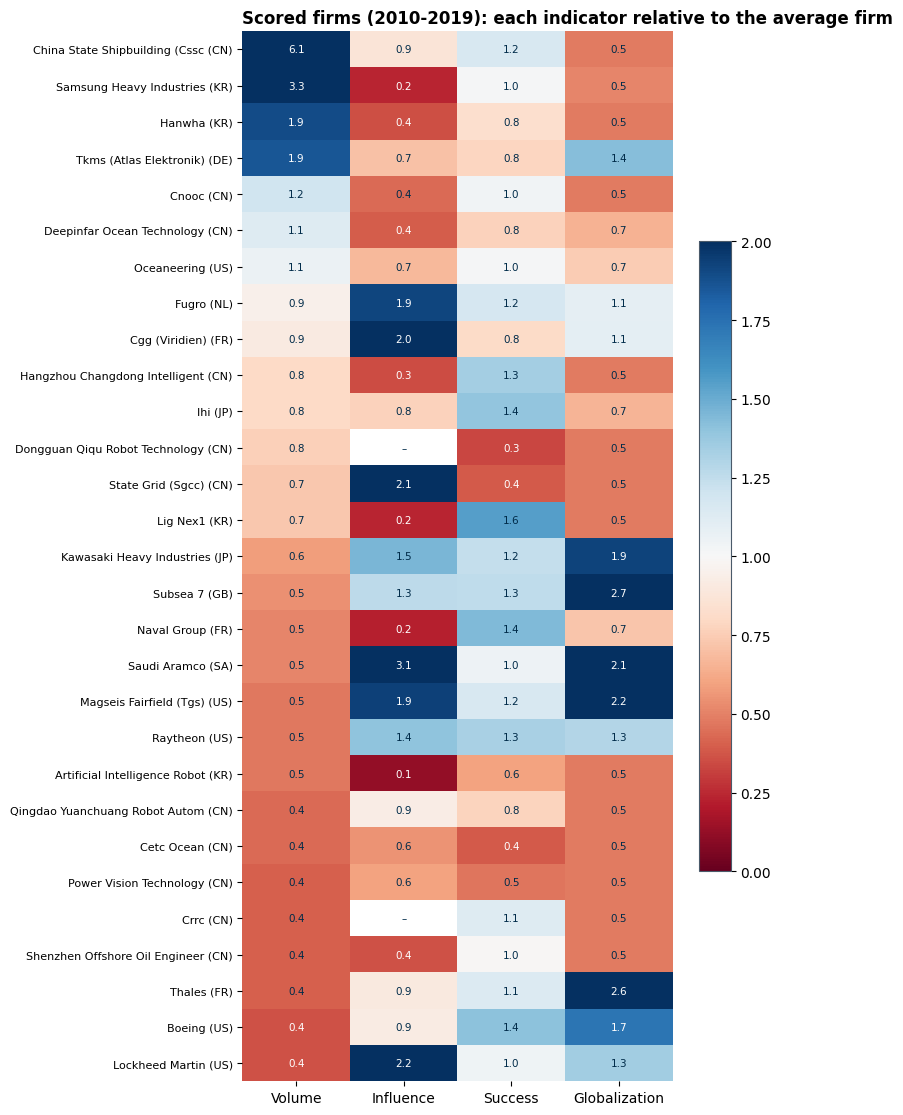

In [5]:
skew = pool["volume"].max() / pool["volume"].median()
print(f"Volume: the largest firm has {skew:.0f} times the median portfolio of the scored firms "
      f"({pool['volume'].idxmax().title()}, {int(pool['families'].max())} families)")
print("Correlation between the indicators (Spearman):")
display(pool[INDICATORS].corr(method="spearman").round(2))

order_v = pool.sort_values("families", ascending=False)
rel = order_v[INDICATORS] / pool[INDICATORS].mean()
fig, ax = plt.subplots(figsize=(8, 0.34 * len(rel) + 1.4))
im = ax.imshow(rel.clip(upper=3).values, cmap="RdBu", vmin=0, vmax=2, aspect="auto")
ax.set_xticks(range(len(INDICATORS)), [k.capitalize() for k in INDICATORS])
ax.set_yticks(range(len(rel)), [f"{n.title()[:30]} ({c})" for n, c in zip(rel.index, order_v.country)], fontsize=8)
for i in range(rel.shape[0]):
    for j in range(rel.shape[1]):
        v = rel.iat[i, j]
        ax.text(j, i, "–" if pd.isna(v) else f"{v:.1f}", ha="center", va="center", fontsize=7.5,
                color="white" if pd.notna(v) and abs(v - 1) > 0.6 else NAVY)
ax.spines[:].set_visible(False)
ax.set_title(f"Scored firms ({WINDOW[0]}-{WINDOW[1]}): each indicator relative to the average firm")
plt.colorbar(im, ax=ax, shrink=0.6)
plt.tight_layout()
plt.savefig(FIG / "s3_indicators_relative.png", dpi=200, bbox_inches="tight")
plt.show()

## 5 · The weights

Tutorial 4: *there is no universal set of weights, each sector needs its own*. Ours come from what Steps 1-2
showed about how this sector uses patents:

- **Volume, 15%.** Counts are inflated by domestic filing: 73% of the families are first filed in China, where
  filing subsidies inflated counts until 2021 (Dang & Motohashi, 2015), and the market leaders file few families
  (1.5.1). Size matters to a buyer, but it is the weakest signal of value here.
- **Globalization, 30%.** Filing abroad is expensive and is done only for inventions worth protecting in the
  client's markets (lecture, *family size*); in a defence sector it also shows which firms sell outside their home
  country, which is what Fincantieri needs from a target.
- **Influence, 35%.** Forward citations are the measure of technological impact closest to the value of the
  knowledge (Trajtenberg, 1990; Harhoff et al., 1999); normalised by year, they are fair to recent families.
- **Success, 20%.** A grant is a check of novelty and inventive step, but grant practices differ by office
  (Tutorial 4, 6.2): a family filed only in China passes one examination, a family filed in five offices five.

Section 7 tests how much the ranking depends on this choice.

In [6]:
w = pd.Series(WEIGHTS, dtype=float)
w = w / w.sum()
print("Weights (normalised):", w.round(2).to_dict())

Weights (normalised): {'influence': 0.35, 'globalization': 0.3, 'success': 0.2, 'volume': 0.15}


## 6 · From four indicators to one ranking

**Method.** Reciprocal Rank Fusion (Cormack et al., 2009; Tutorial 4, 8.5): on each indicator the firms are sorted,
each position is worth $(c+1)/(c+\text{position})$ points with $c$ = number of firms, and the points are added with
the weights; 100 = first on every indicator. A firm with no family old enough for citations is ranked last on
influence. RRF keeps the **order**, not the size of the gaps: the gaps are dominated by a few very large Chinese
state groups on volume, and the bank's question is *who is at the top* (a shortlist).

For comparison, the weighted mean of the ratios to the average firm (A in Tutorial 4), with volume taken as the
**logarithm** of the families to tame its skew.

In [7]:
log_pool = pool.assign(volume=np.log(pool["families"]))
both = pd.DataFrame({"RRF": combine_scores(pool, w, "rrf"), "mean (log volume)": combine_scores(log_pool, w, "mean")})
both["rank RRF"] = final_rank(both["RRF"])
both["rank mean"] = final_rank(both["mean (log volume)"])
rho = both["rank RRF"].corr(both["rank mean"], method="spearman")
print(f"Spearman correlation between the two methods: {rho:.2f}")

pool["score"] = combine_scores(pool, w, "rrf") if METHOD == "rrf" else combine_scores(log_pool, w, "mean")
pool["rank"] = final_rank(pool["score"])
positions = pool[INDICATORS].rank(ascending=False, method="min", na_option="bottom").astype(int).add_prefix("pos. ")
ranking = (pool[["country", "families"] + INDICATORS].join(positions).join(pool[["score", "rank"]])
           .join(both[["rank mean"]]).sort_values("rank"))
display(ranking.round(2))

Spearman correlation between the two methods: 0.98


,country,families,volume,influence,success,globalization,pos. volume,pos. influence,pos. success,pos. globalization,score,rank,rank mean
applicant,,,,,,,,,,,,,
SAUDI ARAMCO,SA,14,0.00,3.43,0.67,4.29,17,1,14,4,86.01,1,1
SUBSEA 7,GB,15,0.00,1.41,0.81,5.60,16,9,7,1,84.30,2,3
MAGSEIS FAIRFIELD (TGS),US,13,0.00,2.16,0.75,4.54,19,5,11,3,83.38,3,2
KAWASAKI HEAVY INDUSTRIES,JP,16,0.00,1.63,0.80,4.00,15,7,8,5,82.08,4,5
FUGRO,NL,26,0.01,2.15,0.75,2.27,8,6,9,11,80.45,5,7
LOCKHEED MARTIN,US,10,0.00,2.47,0.67,2.80,28,2,15,8,79.73,6,4
CGG (VIRIDIEN),FR,25,0.00,2.29,0.52,2.28,9,4,21,10,78.74,7,8
BOEING,US,10,0.00,1.03,0.91,3.60,28,11,3,6,78.61,8,10
RAYTHEON,US,13,0.00,1.57,0.85,2.69,19,8,6,9,78.58,9,9


**What makes each score.** With RRF each indicator contributes $100\cdot w_k\cdot(c+1)/(c+\text{position}_k)$.

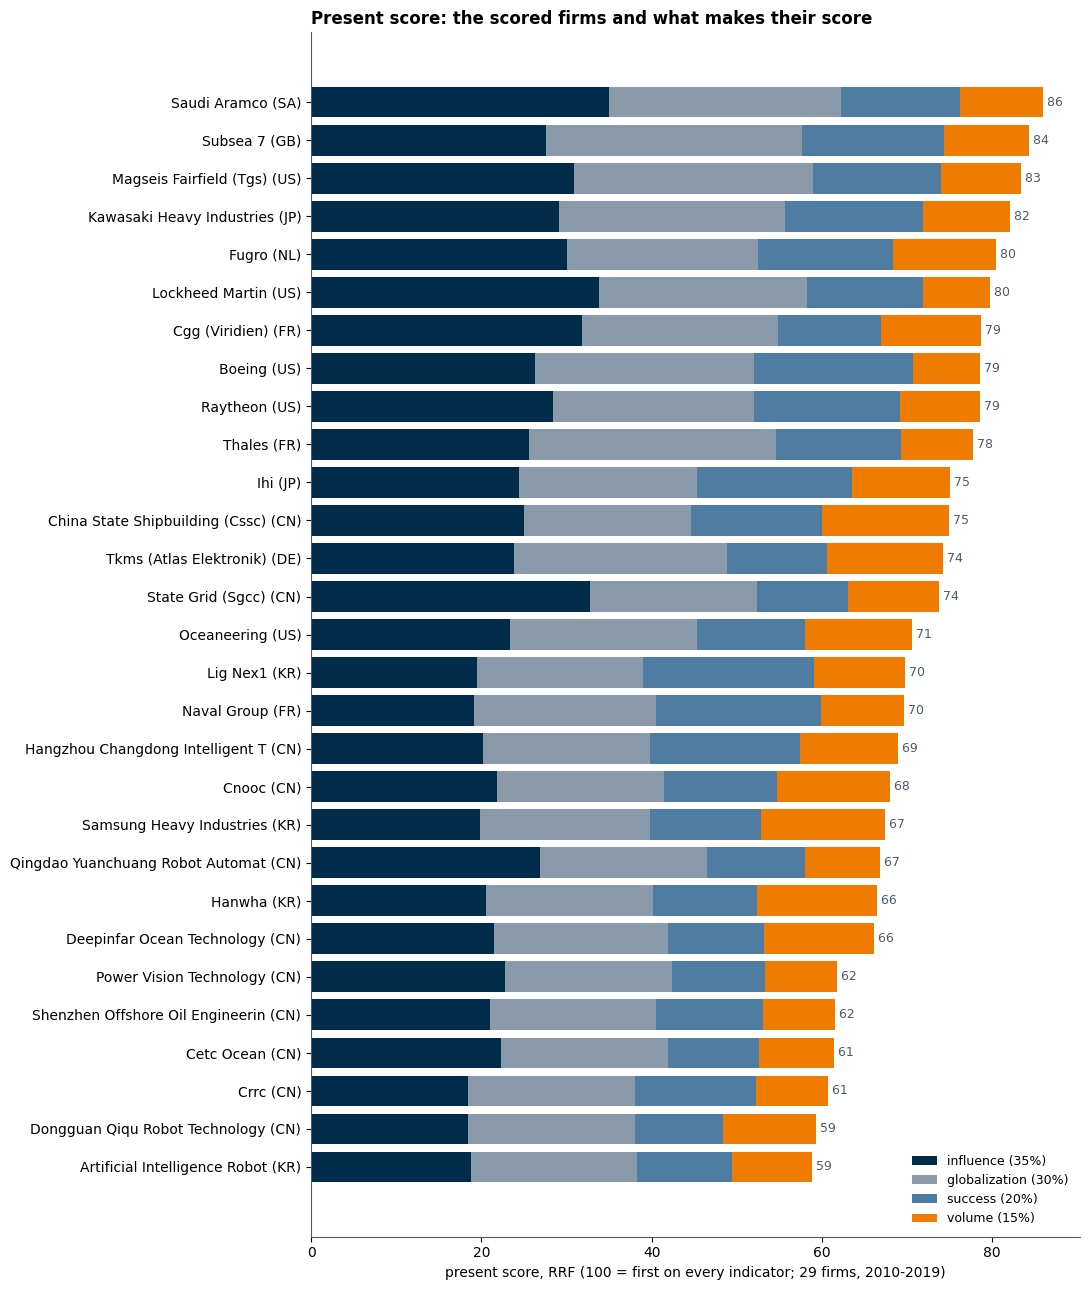

In [8]:
c = len(pool)
pos_all = pool[INDICATORS].rank(ascending=False, method="min", na_option="bottom")
contrib = (w * (c + 1) / (c + pos_all)) * 100
top = pool.sort_values("rank").index[::-1]
fig, ax = plt.subplots(figsize=(11, 0.4 * len(top) + 1.4))
left = np.zeros(len(top))
for k in w.index:
    vals = contrib.loc[top, k].values
    ax.barh([f"{n.title()[:32]} ({pool.at[n, 'country']})" for n in top], vals, left=left, color=COLOURS[k],
            label=f"{k} ({w[k]:.0%})")
    left += vals
for y, x in enumerate(left):
    ax.text(x, y, f" {x:.0f}", va="center", fontsize=9, color=GREY)
ax.set_xlabel(f"present score, RRF (100 = first on every indicator; {c} firms, {WINDOW[0]}-{WINDOW[1]})")
ax.legend(frameon=False, loc="lower right", fontsize=9)
ax.set_title("Present score: the scored firms and what makes their score")
plt.tight_layout()
plt.savefig(FIG / "s3_score_breakdown.png", dpi=200, bbox_inches="tight")
plt.show()

## 7 · Is the ranking robust?

Same method, other assumptions (Tutorial 4, §9-10): equal weights, size first, one indicator left out at a time,
and three refinements brought into the score: the **quadrilateral share** instead of the offices (the Clarivate
measure of globalization, 7.3), **blocking patents** as a fifth indicator (5.4), and the **EP grant rate** instead
of success across offices (6.1, only firms with 5+ EP families have it: the others rank last on it). A firm that
stays at the top under every scheme is a safe recommendation; a firm that jumps owes its position to one
assumption, and the deck must say which.

In [9]:
SCHEMES = {
    "ours": dict(w),
    "equal": {k: 1 for k in INDICATORS},
    "size first": {"influence": 0.15, "globalization": 0.25, "success": 0.20, "volume": 0.40},
    **{f"without {k}": {j: 1 for j in INDICATORS if j != k} for k in INDICATORS},
    "quadrilateral instead of offices": {("quadrilateral_share" if k == "globalization" else k): v for k, v in w.items()},
    "plus blocking patents": {"influence": 0.25, "blocking_share": 0.15, "globalization": 0.25, "success": 0.20, "volume": 0.15},
    "EP grant rate instead of success": {("ep_success" if k == "success" else k): v for k, v in w.items()},
}
by_scheme = pd.DataFrame({name: final_rank(combine_scores(pool, ws, METHOD)) for name, ws in SCHEMES.items()})
by_scheme["mean (log volume)"] = both["rank mean"]

corr = by_scheme.corr(method="spearman")["ours"].drop("ours").round(2).sort_values()
display(corr.to_frame("Spearman with our ranking"))

TOP_K = 10
stable = by_scheme.apply(lambda r: (r <= TOP_K).mean(), axis=1).rename(f"share of schemes in top {TOP_K}")
spread = pd.DataFrame({"rank": by_scheme["ours"], "best": by_scheme.min(axis=1), "worst": by_scheme.max(axis=1)}).join(stable)
display(spread.sort_values("rank"))

,Spearman with our ranking
without influence,0.65
size first,0.70
without globalization,0.81
without success,0.87
quadrilateral instead of offices,0.92
EP grant rate instead of success,0.94
equal,0.95
without volume,0.95
plus blocking patents,0.97
mean (log volume),0.98


,rank,best,worst,share of schemes in top 10
applicant,,,,
SAUDI ARAMCO,1,1,15,0.909091
SUBSEA 7,2,1,11,0.909091
MAGSEIS FAIRFIELD (TGS),3,1,10,1.000000
KAWASAKI HEAVY INDUSTRIES,4,3,8,1.000000
FUGRO,5,2,9,1.000000
LOCKHEED MARTIN,6,2,22,0.636364
CGG (VIRIDIEN),7,2,19,0.818182
BOEING,8,4,19,0.636364
RAYTHEON,9,6,14,0.727273


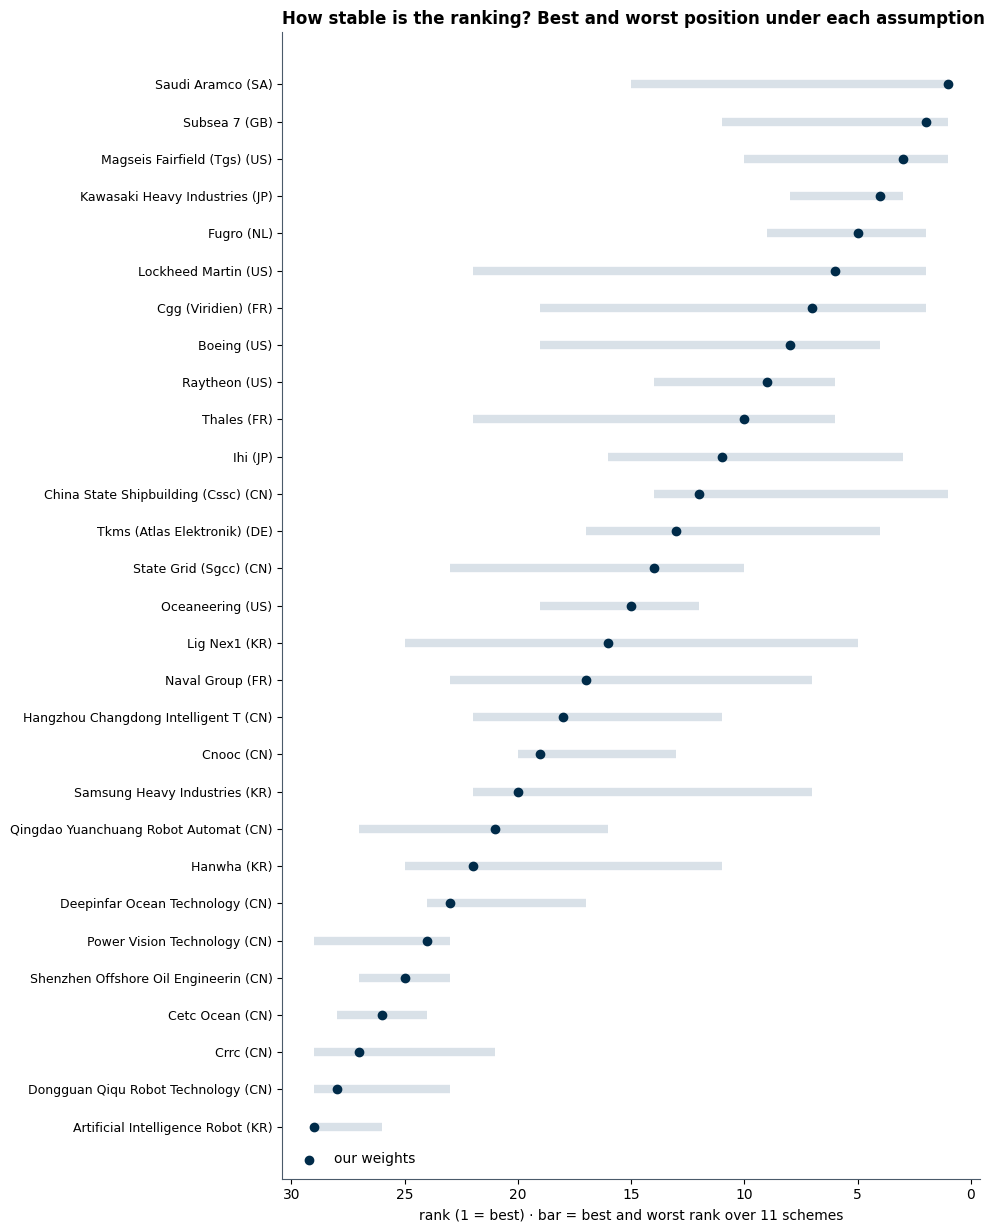

In [10]:
show = spread.sort_values("rank")
fig, ax = plt.subplots(figsize=(10, 0.38 * len(show) + 1.4))
ys = np.arange(len(show))[::-1]
ax.hlines(ys, show["best"], show["worst"], color=LIGHT, lw=6)
ax.scatter(show["rank"], ys, color=NAVY, zorder=3, label="our weights")
ax.set_yticks(ys, [f"{n.title()[:32]} ({pool.at[n, 'country']})" for n in show.index], fontsize=9)
ax.invert_xaxis()
ax.set_xlabel(f"rank (1 = best) · bar = best and worst rank over {by_scheme.shape[1]} schemes")
ax.legend(frameon=False, loc="lower left")
ax.set_title("How stable is the ranking? Best and worst position under each assumption")
plt.tight_layout()
plt.savefig(FIG / "s3_rank_robustness.png", dpi=200, bbox_inches="tight")
plt.show()

## 8 · References: the client and the market leaders

The client and the market leaders of 1.5.1 are not in the ranking: the client is the buyer, and most leaders file
fewer than `MIN_FAMILIES` families in the window. To place them, each one is **added alone** to the scored firms
and ranked with the same method and weights (a leader already scored keeps its rank). With so few families their
indicators are an order of magnitude, not a measure.

In [11]:
rows = []
for name in [CLIENT] + [f for f in REFERENCE_FIRMS if f != CLIENT]:
    if name not in firm_table.index:
        rows.append({"firm": name, "families": 0, "rank": "no family in the window"})
        continue
    r = firm_table.loc[name]
    if name in pool.index:
        where, n = int(pool.at[name, "rank"]), len(pool)
    else:
        t = pd.concat([pool[INDICATORS], r[INDICATORS].to_frame().T.astype(float)])
        where, n = int(final_rank(combine_scores(t, w, METHOD))[name]), len(t)
    rows.append({"firm": name, "country": r["country"], "families": int(r["families"]), "in the ranking": name in pool.index,
                 "rank": f"{where} of {n}", **r[INDICATORS + ["quadrilateral_share"]].astype(float).round(3).to_dict()})
references = pd.DataFrame(rows).set_index("firm")
display(references)

,country,families,in the ranking,rank,volume,influence,success,globalization,quadrilateral_share
firm,,,,,,,,,
FINCANTIERI,IT,2,False,22 of 30,0.000,0.147,0.833,2.500,0.0
KONGSBERG,NO,5,False,19 of 30,0.001,0.991,0.600,2.600,0.0
TELEDYNE,US,5,False,24 of 30,0.001,0.604,0.567,1.400,0.0
SAAB,SE,6,False,15 of 30,0.001,0.959,0.750,2.500,0.0
GENERAL DYNAMICS (BLUEFIN),US,4,False,6 of 30,0.001,1.370,0.938,3.000,0.0
L3HARRIS,US,7,False,22 of 30,0.001,0.000,1.000,1.143,0.0
HUNTINGTON INGALLS (HYDROID),NaN,0,NaN,no family in the window,NaN,NaN,NaN,NaN,NaN
EXAIL (ECA),FR,7,False,15 of 30,0.001,0.393,0.893,3.286,0.0


## 9 · Below the gate: young firms (Step 4) and established firms with few families

The firms of the Step 2 shortlist (10+ families over 2000-2025) that are below the gate in the window split in two:

- **young firms**: first family in the sector from 2015 (`split_year`, the entrants of Step 2). Most of their
  portfolio is filed after 2019, too recent to be judged on grants and citations; their value lies in what they file
  now, which is what the **future score** (Step 4) measures;
- **established firms with few families in the window** (e.g. BAE Systems with 9, Saab, Exail): not young, just
  below the gate. They are listed for the deck, and the market leaders among them are placed in Section 8.

In [12]:
short = pd.read_csv(IN2 / "shortlist_step3.csv", index_col="applicant")
short.index = short.index.map(to_group)
SPLIT_YEAR = int(C.LANDSCAPE.get("split_year", 2015))
below = short[~short.index.isin(pool.index) & ~short["is client"].astype(bool)].copy()
below["families in window"] = firm_table["families"].reindex(below.index).fillna(0).astype(int)
COLS = ["country", "families", "families in window", "first year", "momentum (pp)", "international share",
        "block-6-only share"]
step4 = below[below["first year"] >= SPLIT_YEAR].sort_values("families", ascending=False)[COLS]
established = below[below["first year"] < SPLIT_YEAR].sort_values("families in window", ascending=False)[COLS]
print(f"{len(step4)} young firms (first family from {SPLIT_YEAR}) · {len(established)} established firms below the gate")
display(step4.head(15).round(2))
display(established.round(2))

41 young firms (first family from 2015) · 16 established firms below the gate


,country,families,families in window,first year,momentum (pp),international share,block-6-only share
applicant,,,,,,,
CHINA HUANENG GROUP,CN,57,0,2020,0.25,0.04,0.25
CHINA YANGTZE POWER,CN,43,1,2019,0.14,0.02,0.35
ROBOSEA BEIJING ROBOT SCIENCE AND TECHNOLOGY,CN,38,8,2016,0.43,0.03,0.13
GUANGDONG POWER GRID,CN,26,0,2020,0.03,0.00,0.15
CGN (CHINA GENERAL NUCLEAR POWER),CN,24,7,2016,-0.03,0.04,0.46
KUNMING HAIWEI ELECTROMECHANICAL TECHNOLOGY RESEARCH INSTITUTE,CN,24,1,2019,0.14,0.00,0.50
QINGDAO PENGPAI OCEAN EXPLORATION TECHNOLOGY,CN,19,1,2019,0.21,0.00,0.26
SHENGDONG RUDONG OFFSHORE WIND POWER GENERATION,CN,19,0,2022,0.09,0.00,0.16
TIANJIN HANHAI LANFAN MARINE TECHNOLOGY,CN,19,8,2017,-0.08,0.00,0.21


,country,families,families in window,first year,momentum (pp),international share,block-6-only share
applicant,,,,,,,
BAE SYSTEMS,GB,41,9,2001,0.20,0.34,0.07
ONESUBSEA,GB,11,9,2009,-0.18,0.91,0.00
MITSUBISHI HEAVY INDUSTRIES,JP,20,7,2000,0.03,0.25,0.65
EXAIL (ECA),FR,14,7,2011,0.04,1.00,0.07
HYUNDAI HEAVY INDUSTRIES,KR,10,7,2008,-0.12,0.10,0.60
MITSUI ENGINEERING AND SHIPBUILDING,JP,16,6,2001,-0.08,0.00,0.50
SAAB,SE,12,6,2007,-0.14,0.83,0.00
DAEYANG ELECTRIC,KR,10,6,2012,0.01,0.00,0.20
QINGDAO ROBOTFISH MARINE TECHNOLOGY,CN,10,6,2014,-0.02,0.00,0.30


## 10 · Exports

`present_score.csv` holds the score and the rank of each scored firm (y axis of the Magic Quadrant, Step 5), with
the four indicators, their positions, the refinements and the stability over the robustness schemes.

In [13]:
EXTRAS = ["quadrilateral_share", "blocking_share", "blocking families", "ep_success", "EP families", "ep_states",
          "volume_change", "international share", "families with citation window"]
export = (pool[["country", "families"] + INDICATORS + ["score", "rank"]].join(positions).join(pool[EXTRAS])
          .join(spread[["best", "worst", f"share of schemes in top {TOP_K}"]]).sort_values("rank"))
export.to_csv(OUT / "present_score.csv")
firm_table.to_csv(TAB / "present_score_all_companies.csv")
by_scheme.sort_values("ours").to_csv(TAB / "present_score_robustness.csv")
corr.to_frame("Spearman with our ranking").to_csv(TAB / "present_score_scheme_correlation.csv")
references.to_csv(TAB / "present_score_references.csv")
step4.to_csv(OUT / "step4_young_firms.csv")
established.to_csv(TAB / "present_score_below_gate_established.csv")
v0 = OUT / "present_score_v0.csv"          # the first version, built on the Step 2 shortlist (kept for comparison)
if v0.exists():
    old = pd.read_csv(v0, index_col=0)["rank"]
    common = export.index.intersection(old.index)
    print(f"v0 vs this version: {len(common)} firms in both, Spearman {export.loc[common, 'rank'].corr(old[common], method='spearman'):.2f}")

KEY = {
    "version": "v1 (step1 tables)", "window": list(WINDOW), "min_families": MIN_FAMILIES,
    "method": METHOD, "weights": {k: round(v, 3) for k, v in w.items()},
    "families_in_window": int(len(win)), "firms_scored": int(len(pool)), "firms_young_step4": int(len(step4)), "firms_established_below_gate": int(len(established)),
    "volume_max_over_median": round(float(skew), 1),
    "spearman_rrf_vs_mean": round(float(rho), 3),
    "spearman_min_across_schemes": round(float(corr.min()), 3),
    "scheme_least_correlated": corr.idxmin(),
    "top10": [f"{n} ({pool.at[n, 'country']})" for n in export.index[:10]],
    "top10_stable_in_all_schemes": [n for n in export.index[:10] if spread.at[n, "worst"] <= TOP_K],
    "references": references["rank"].to_dict(),
}
(OUT / "key_numbers.json").write_text(json.dumps(KEY, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(KEY, indent=2, ensure_ascii=False))

v0 vs this version: 27 firms in both, Spearman 0.93
{
  "version": "v1 (step1 tables)",
  "window": [
    2010,
    2019
  ],
  "min_families": 10,
  "method": "rrf",
  "weights": {
    "influence": 0.35,
    "globalization": 0.3,
    "success": 0.2,
    "volume": 0.15
  },
  "families_in_window": 5176,
  "firms_scored": 29,
  "firms_young_step4": 41,
  "firms_established_below_gate": 16,
  "volume_max_over_median": 10.5,
  "spearman_rrf_vs_mean": 0.978,
  "spearman_min_across_schemes": 0.65,
  "scheme_least_correlated": "without influence",
  "top10": [
    "SAUDI ARAMCO (SA)",
    "SUBSEA 7 (GB)",
    "MAGSEIS FAIRFIELD (TGS) (US)",
    "KAWASAKI HEAVY INDUSTRIES (JP)",
    "FUGRO (NL)",
    "LOCKHEED MARTIN (US)",
    "CGG (VIRIDIEN) (FR)",
    "BOEING (US)",
    "RAYTHEON (US)",
    "THALES (FR)"
  ],
  "top10_stable_in_all_schemes": [
    "MAGSEIS FAIRFIELD (TGS)",
    "KAWASAKI HEAVY INDUSTRIES",
    "FUGRO"
  ],
  "references": {
    "FINCANTIERI": "22 of 30",
    "KONGSBERG": "

## 11 · To state in the technical appendix

- *Window and gate*: priority years 2010-2019, at least 10 families in the window; full counting of co-owned
  families. Influence uses only the families with a complete 5-year citation window (priority year + 5 ≤ 2022,
  `02_clean`), so it rests on 2010-2017.
- *Success* across offices (one examination per office), not the EP rate: the sector is mostly filed in China. The
  EP rate is a robustness check for the firms with 5+ EP families.
- *Globalization* without PCT requests and EP translations; EP counts as one office.
- *EP states* from renewal fees paid (`PGFP`): a lower bound, the lapses (`PG25`) carry no reason in our extract.
- *Blocking* on X citations only (I is not separated in `02_clean`).
- *Combination*: RRF with c = number of firms; weights and their reasons in Section 5; robustness over the schemes
  of Section 7.
- The present score ranks **patent portfolios**, not firms' market value: market leaders protect much of their
  value through secrecy, lead time and defence procurement (1.5.6), and appear here only as references.